In [1]:
import os
import pandas as pd

if not os.path.exists('dataset_sms_spam_v1.csv'):
    from google.colab import files
    files.upload()

df = pd.read_csv('dataset_sms_spam_v1.csv')
print(df.isnull().sum())

Saving dataset_sms_spam_v1.csv to dataset_sms_spam_v1.csv
teks     0
label    0
dtype: int64


In [2]:
print('Duplikat awal:', df.duplicated().sum())
df = df.dropna(subset=['teks', 'label']).copy()
df['teks'] = df['teks'].astype(str).str.lower().str.strip()
df['label'] = df['label'].astype(int)
df = df.drop_duplicates(subset='teks')
print('Total data bersih:', len(df))

Duplikat awal: 1
Total data bersih: 1142


In [4]:
kelas = ['Normal', 'Penipuan', 'spam']
distribusi = df['label'].value_counts().sort_index()
print(pd.DataFrame({'Kategori': kelas, 'Jumlah': distribusi.values}))

   Kategori  Jumlah
0    Normal     568
1  Penipuan     335
2      spam     239


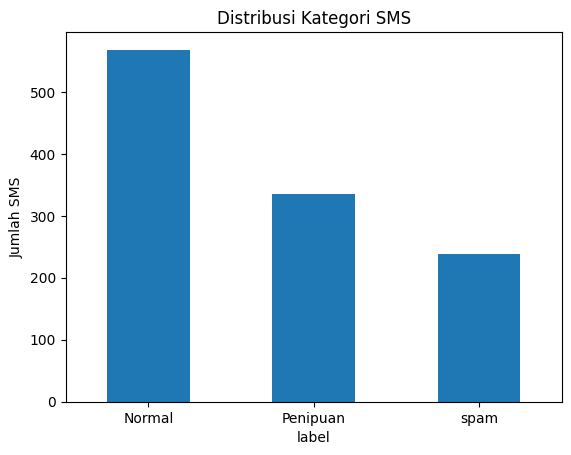

Data latih: 913 | Data uji: 229

Naive Bayes [0.908 0.86  0.925 0.939 0.904] Rata-Rata 0.9072
Akurasi: 0.9214
              precision    recall  f1-score   support

      Normal       0.94      0.98      0.96       114
    Penipuan       0.92      0.88      0.90        67
        spam       0.87      0.83      0.85        48

    accuracy                           0.92       229
   macro avg       0.91      0.90      0.90       229
weighted avg       0.92      0.92      0.92       229



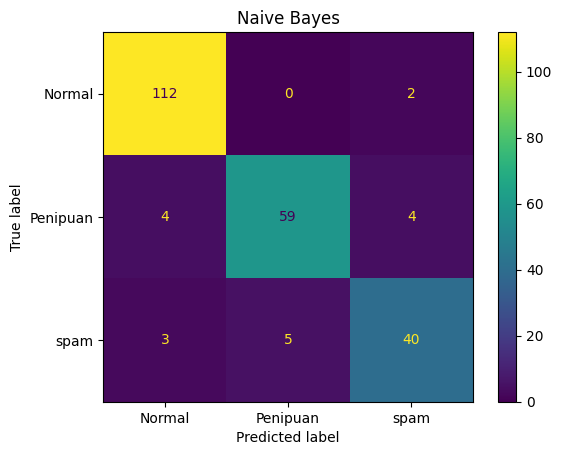

Akurasi data latih: 0.9956
Akurasi data uji  : 0.9214

--------------------------------------------------

Logistic Regression [0.891 0.834 0.943 0.943 0.912] Rata-Rata 0.9046
Akurasi: 0.917
              precision    recall  f1-score   support

      Normal       0.94      0.98      0.96       114
    Penipuan       0.91      0.88      0.89        67
        spam       0.87      0.81      0.84        48

    accuracy                           0.92       229
   macro avg       0.91      0.89      0.90       229
weighted avg       0.92      0.92      0.92       229



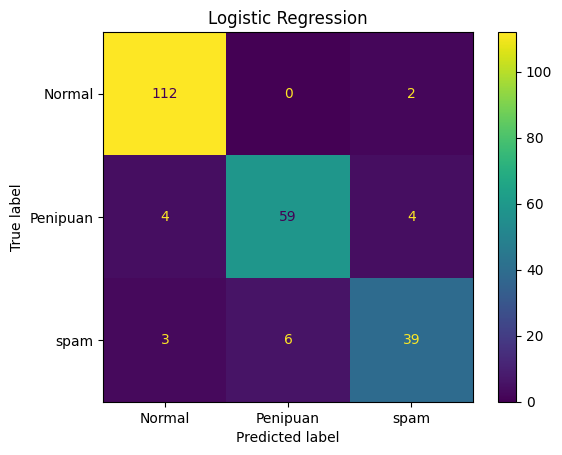

Akurasi data latih: 0.9967
Akurasi data uji  : 0.917

--------------------------------------------------



In [5]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

distribusi.plot(kind='bar', title='Distribusi Kategori SMS')
plt.xticks([0, 1, 2], kelas, rotation=0)
plt.ylabel('Jumlah SMS')
plt.show()

X = df['teks']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Data latih:', len(X_train), '| Data uji:', len(X_test))
print()

models = {
    'Naive Bayes': make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB()),
    'Logistic Regression': make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000)),
}

hasil_model = []

for name, model in models.items():
    s = cross_val_score(model, X, y, cv=5)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc_train = model.score(X_train, y_train)
    acc_test = accuracy_score(y_test, pred)

    hasil_model.append({
        'Model': name,
        'CV Rata-rata': round(s.mean(), 4),
        'Akurasi Latih': round(acc_train, 4),
        'Akurasi Uji': round(acc_test, 4),
    })

    print(name, s.round(3), 'Rata-Rata', s.mean().round(4))
    print('Akurasi:', round(acc_test, 4))
    print(classification_report(y_test, pred, target_names=kelas))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=kelas)
    plt.title(name)
    plt.show()

    print('Akurasi data latih:', round(acc_train, 4))
    print('Akurasi data uji  :', round(acc_test, 4))
    print()
    print('-' * 50)
    print()

In [9]:
print('Tabel Perbandingan Model:')
display(pd.DataFrame(hasil_model))

nb = models['Naive Bayes']
pred_nb = nb.predict(X_test)
label_map = {0: 'Normal', 1: 'Penipuan', 2: 'spam'}

tabel_uji = pd.DataFrame({
    'Teks SMS': X_test.values,
    'Label Asli': [label_map[i] for i in y_test],
    'Prediksi': [label_map[i] for i in pred_nb],
})
tabel_uji['Status'] = ['Benar' if a == p else 'Salah' for a, p in zip(tabel_uji['Label Asli'], tabel_uji['Prediksi'])]

print('\nTabel Sampel Hasil Uji Dataset:')
display(tabel_uji.head(15))

Tabel Perbandingan Model:


,Model,CV Rata-rata,Akurasi Latih,Akurasi Uji
0,Naive Bayes,0.9072,0.9956,0.9214
1,Logistic Regression,0.9046,0.9967,0.9170



Tabel Sampel Hasil Uji Dataset:


,Teks SMS,Label Asli,Prediksi,Status
0,segera dptkan ijazah d3-s1-s2 asli terdaftar &...,Penipuan,Penipuan,Benar
1,coba siapa yg lagi di prodi? punten liatin jad...,Normal,Normal,Benar
2,awal bulan saat nya anda eksis lebih lama! int...,spam,spam,Benar
3,karena saya lagi si surabaya sampai besok.. ha...,Normal,Normal,Benar
4,registrasi gagal. harap masukan tanggal yang b...,Normal,Normal,Benar
5,nasabah bri yth. norek anda terpilih sebagai p...,Penipuan,Penipuan,Benar
6,pesan resmi pt.3care indonesia berkat isi ulan...,Penipuan,Penipuan,Benar
7,yth kpd bpk/ibu sy eka novitasari kariyawan 3c...,Penipuan,Penipuan,Benar
8,selamat!anda mndptkan hadiah cektunai rp. 15jt...,Penipuan,Penipuan,Benar
9,surat keputusan pt.tri care slamat no.anda res...,Penipuan,Penipuan,Benar


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [7]:
vec = nb.named_steps['tfidfvectorizer']
clf = nb.named_steps['multinomialnb']
fitur = vec.get_feature_names_out()

for i, nama_kelas in enumerate(kelas):
    top_idx = clf.feature_log_prob_[i].argsort()[-10:][::-1]
    print(f'Top 10 kata ({nama_kelas}):', ', '.join(fitur[top_idx]))

Top 10 kata (Normal): aku, nama1, ada, yg, mau, aja, ya, di, nya, ga
Top 10 kata (Penipuan): anda, no, info, pin, www, hadiah, com, klik, klik www, ke
Top 10 kata (spam): di, paket, kuota, utk, sms, hari, tsel, bonus, promo, beli


In [10]:
while True:
    sms = input("masukkan kalimat ( 'k'=berhenti): ").strip()
    if sms.lower() == 'k':
        break
    if sms:
        hasil = nb.predict([sms.lower()])[0]
        print('Hasil deteksi:', label_map[hasil])

masukkan kalimat ( 'k'=berhenti): ppppp
Hasil deteksi: Normal
masukkan kalimat ( 'k'=berhenti): hari ini ad paket datang
Hasil deteksi: Normal
masukkan kalimat ( 'k'=berhenti): kouta anda habis ayo beli lagi
Hasil deteksi: Normal
masukkan kalimat ( 'k'=berhenti): paket anda habis ayo buruan isi ulang kouta tsel anda
Hasil deteksi: spam
masukkan kalimat ( 'k'=berhenti): k
